# Glacial erosion: results

The diagnostic glacial model of goSPL on a mountain range: ice grows above the equilibrium-line altitude (ELA), slides by Glen's law and abrades its bed; rivers and hillslopes act below. This notebook reads the pre-computed run `sim_glacier` (run it with `gospl -i input-glacier.yml`) and draws the result after 10 outputs.

## The figure

Glacial-erosion example figure (fig_ex_glacier.pdf) for the GMD paper, from the
pre-computed glacial_erosion run (sim_glacier). goSPL's diagnostic glacial model
grows ice above the equilibrium-line altitude, slides it (Glen law) and abrades the
bed. Post-processed with gospl.analyse.gridexport.grid_export. Panels:
(a) ice thickness with the ELA contour,  (b) basal sliding velocity,
(c) cumulative erosion/deposition,  (d) a cross-valley transect (initial vs final
topography with the diagnosed glacier).

iceH<= 113 m | Ub<= 60.247 m/yr | edmax 50.0


wrote fig_ex_glacier.pdf / .png  | transect y-row 609


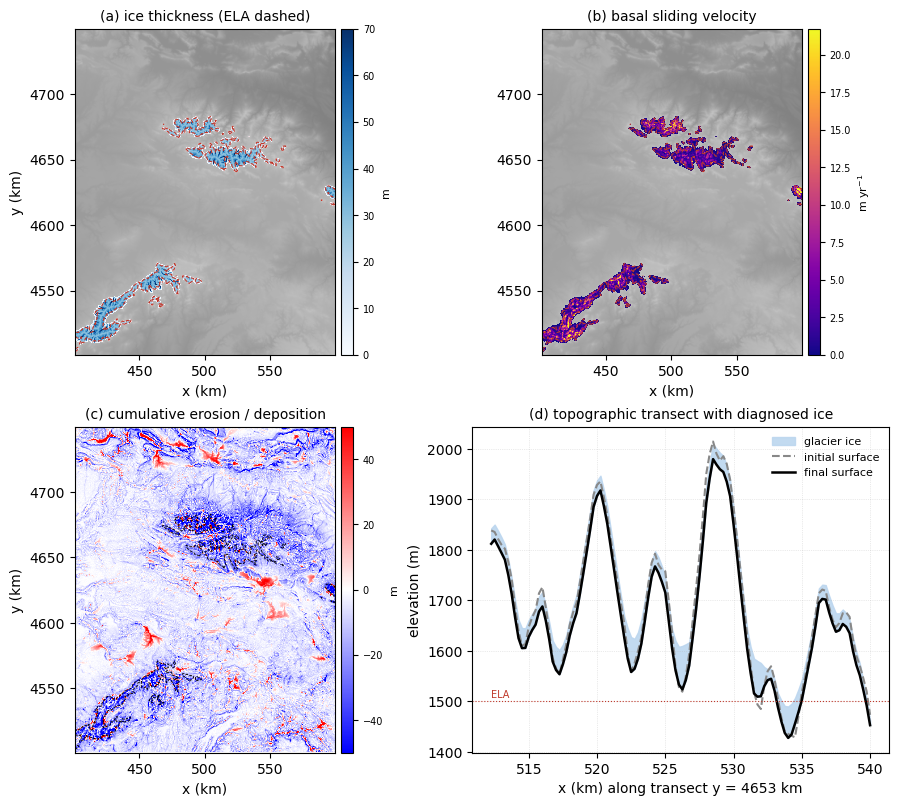

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1 import make_axes_locatable
from gospl.analyse.gridexport import grid_export

EX = os.getcwd()
H5, MESH, RESO, ELA = os.path.join(EX, "sim_glacier/h5"), os.path.join(EX, "data/gospl_mesh.npz"), 250, 1500.0

g0 = grid_export(H5, MESH, 0, spacing=RESO)
g = grid_export(H5, MESH, 10, spacing=RESO)
x, y = np.asarray(g["x"]) / 1e3, np.asarray(g["y"]) / 1e3

def arr(gg, key):
    f = np.array(gg[key], float); m = np.asarray(gg["mask"], bool)
    return np.where(m, f, np.nan) if m.shape == f.shape else f
elev, elev0 = arr(g, "elev"), arr(g0, "elev")
iceH, iceUb, iceAbr, erodep = arr(g, "iceH"), arr(g, "iceUb"), arr(g, "iceAbr"), arr(g, "erodep")
ice_ext = np.where(iceH > 1.0, iceH, np.nan)          # glacier extent (>1 m)
hvmax = round(float(np.nanpercentile(iceH[iceH > 1.0], 99)), -1) or 100.0
uvmax = float(np.nanpercentile(iceUb[iceH > 1.0], 99))
edmax = round(float(np.nanpercentile(np.abs(erodep), 98)), -1) or 50.0
print(f"iceH<= {np.nanmax(iceH):.0f} m | Ub<= {np.nanmax(iceUb):.3f} m/yr | edmax {edmax}")

fig = plt.figure(figsize=(11.4, 9.4))
gs = GridSpec(2, 2, figure=fig, hspace=0.22, wspace=0.12)

def cbar(ax, im, label):
    cax = make_axes_locatable(ax).append_axes("right", size="4.5%", pad=0.06)
    cb = fig.colorbar(im, cax=cax); cb.set_label(label, fontsize=8); cb.ax.tick_params(labelsize=7)

def bg(ax):
    ax.pcolormesh(x, y, elev, cmap="gray", vmin=0, vmax=2600, shading="auto",
                  rasterized=True, alpha=0.55)
    ax.contour(x, y, elev, levels=[ELA], colors="#c0392b", linewidths=0.8, linestyles="--")
    ax.set_aspect("equal"); ax.set_xlabel("x (km)")

# --- (a) ice thickness + ELA -----------------------------------------------
axa = fig.add_subplot(gs[0, 0]); bg(axa); axa.set_ylabel("y (km)")
im = axa.pcolormesh(x, y, ice_ext, cmap="Blues", vmin=0, vmax=hvmax, shading="auto", rasterized=True)
axa.set_title("(a) ice thickness (ELA dashed)", fontsize=10); cbar(axa, im, "m")

# --- (b) basal sliding velocity --------------------------------------------
axb = fig.add_subplot(gs[0, 1]); bg(axb)
im = axb.pcolormesh(x, y, np.where(iceH > 1.0, iceUb, np.nan), cmap="plasma",
                    vmin=0, vmax=uvmax, shading="auto", rasterized=True)
axb.set_title("(b) basal sliding velocity", fontsize=10); cbar(axb, im, "m yr$^{-1}$")

# --- (c) cumulative erosion / deposition -----------------------------------
axc = fig.add_subplot(gs[1, 0]); axc.set_aspect("equal"); axc.set_xlabel("x (km)"); axc.set_ylabel("y (km)")
im = axc.pcolormesh(x, y, erodep, cmap="bwr", vmin=-edmax, vmax=edmax, shading="auto", rasterized=True)
axc.contour(x, y, elev, levels=[ELA], colors="k", linewidths=0.6, linestyles="--")
axc.set_title("(c) cumulative erosion / deposition", fontsize=10); cbar(axc, im, "m")

# --- (d) cross-valley transect (V -> U) ------------------------------------
# transect through the most heavily glaciated column (max column ice volume)
gx, gy = np.asarray(g["x"]), np.asarray(g["y"])
col_ice = np.nansum(np.where(np.isfinite(ice_ext), ice_ext, 0.0), axis=1)   # per y-row
iyc = int(np.argmax(col_ice))
half = int(14e3 / (gx[1] - gx[0]))
ic = int(np.nanargmax(np.where(iyc == iyc, np.where(np.isfinite(ice_ext[iyc]), ice_ext[iyc], 0.0), 0.0)))
i0, i1 = max(ic - half, 0), min(ic + half, gx.size - 1)
xt = gx[i0:i1] / 1e3
z0, z1 = elev0[iyc, i0:i1], elev[iyc, i0:i1]
hice = np.where(np.isfinite(ice_ext[iyc, i0:i1]), ice_ext[iyc, i0:i1], 0.0)
axd = fig.add_subplot(gs[1, 1])
axd.fill_between(xt, z1, z1 + hice, color="#bcd6ef", alpha=0.9, label="glacier ice")
axd.plot(xt, z0, color="#888", lw=1.5, ls="--", label="initial surface")
axd.plot(xt, z1, color="k", lw=1.8, label="final surface")
axd.axhline(ELA, color="#c0392b", lw=0.8, ls=":")
axd.text(xt[0], ELA + 8, "ELA", color="#c0392b", fontsize=7)
axd.set_xlabel(f"x (km) along transect y = {gy[iyc]/1e3:.0f} km")
axd.set_ylabel("elevation (m)")
axd.set_title("(d) topographic transect with diagnosed ice", fontsize=10)
axd.legend(fontsize=8, frameon=False, loc="upper right")
axd.grid(True, ls=":", lw=0.5, alpha=0.5)

# fig.savefig("fig_ex_glacier.pdf", bbox_inches="tight")
# fig.savefig("fig_ex_glacier.png", dpi=150, bbox_inches="tight")
print("wrote fig_ex_glacier.pdf / .png  | transect y-row", iyc)
plt.show()